---

## Setup

The California Housing dataset: 20,640 block groups, 8 features and the median house value. we are not using labels, so the house value is kept as a ninth feature.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing
from scipy import stats

plt.style.use('dark_background')
np.random.seed(42)

california = fetch_california_housing()
X = np.column_stack([california.data, california.target])


In [ ]:
X

array([[   8.3252    ,   41.        ,    6.98412698, ...,   37.88      ,
        -122.23      ,    4.526     ],
       [   8.3014    ,   21.        ,    6.23813708, ...,   37.86      ,
        -122.22      ,    3.585     ],
       [   7.2574    ,   52.        ,    8.28813559, ...,   37.85      ,
        -122.24      ,    3.521     ],
       ...,
       [   1.7       ,   17.        ,    5.20554273, ...,   39.43      ,
        -121.22      ,    0.923     ],
       [   1.8672    ,   18.        ,    5.32951289, ...,   39.43      ,
        -121.32      ,    0.847     ],
       [   2.3886    ,   16.        ,    5.25471698, ...,   39.37      ,
        -121.24      ,    0.894     ]])

In [ ]:
X[0]

array([   8.3252    ,   41.        ,    6.98412698,    1.02380952,
        322.        ,    2.55555556,   37.88      , -122.23      ,
          4.526     ])

In [ ]:
feature_names = list(california.feature_names) + ['MedHouseVal']
feature_names

['MedInc',
 'HouseAge',
 'AveRooms',
 'AveBedrms',
 'Population',
 'AveOccup',
 'Latitude',
 'Longitude',
 'MedHouseVal']

In [ ]:
# ndim : number of dimensions
print(f"X: ndim = {X.ndim}, shape = {X.shape}  (samples, features)\n")
for i, name in enumerate(feature_names):
    print(f"  {i}: {name:<12} min = {X[:, i].min():>9.2f}   max = {X[:, i].max():>10.2f}")

X: ndim = 2, shape = (20640, 9)  (samples, features)

  0: MedInc       min =      0.50   max =      15.00
  1: HouseAge     min =      1.00   max =      52.00
  2: AveRooms     min =      0.85   max =     141.91
  3: AveBedrms    min =      0.33   max =      34.07
  4: Population   min =      3.00   max =   35682.00
  5: AveOccup     min =      0.69   max =    1243.33
  6: Latitude     min =     32.54   max =      41.95
  7: Longitude    min =   -124.35   max =    -114.31
  8: MedHouseVal  min =      0.15   max =       5.00


---

## Part 2: Matrices as Transformations

### Example 2: Rotating and scaling a whole dataset

Longitude and Latitude plotted together draw the map of California. A 2 × 2 matrix `M` is applied to every sample at once with `P @ M.T`.

- Rotation by θ: `[[cos θ, −sin θ], [sin θ, cos θ]]`
- Scaling: `[[sx, 0], [0, sy]]`

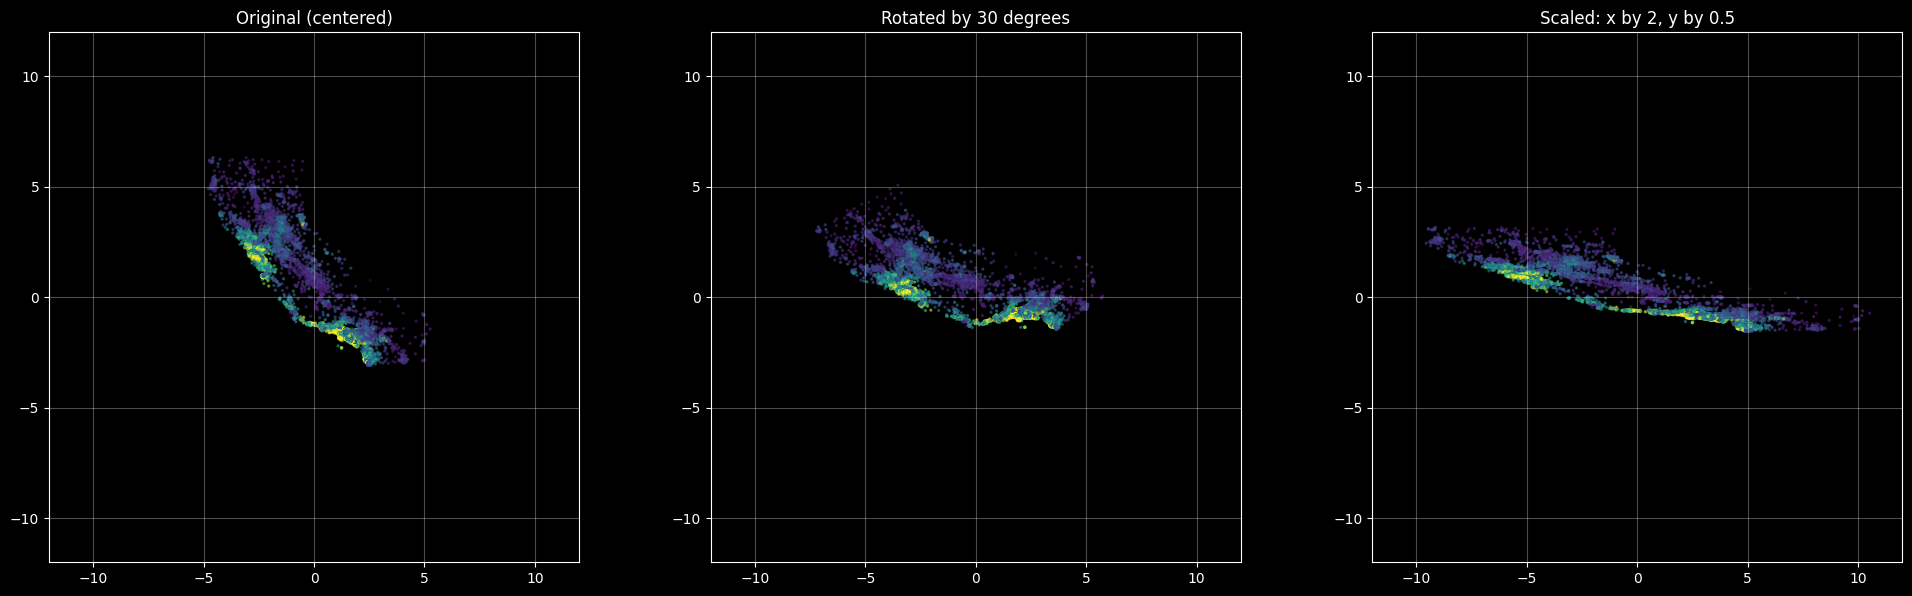

Distance between sample 0 and sample 10000:
  original: 1.6193
  rotated:  1.6193
  scaled:   2.3696


In [ ]:
P = X[:, [7, 6]]                     # Longitude (x), Latitude (y)
P_centered = P - P.mean(axis=0)      # rotation is around the origin

theta = np.deg2rad(30)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
S = np.array([[2.0, 0.0],
              [0.0, 0.5]])

P_rotated = P_centered @ R.T         # (20640, 2) @ (2, 2) -> (20640, 2)
P_scaled = P_centered @ S.T

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
for ax, pts, title in zip(axes, [P_centered, P_rotated, P_scaled],
                          ['Original (centered)', 'Rotated by 30 degrees', 'Scaled: x by 2, y by 0.5']):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.5, c=X[:, 8], cmap='viridis')
    ax.set_title(title)
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

i, j = 0, 10000
print(f"Distance between sample {i} and sample {j}:")
print(f"  original: {np.linalg.norm(P_centered[i] - P_centered[j]):.4f}")
print(f"  rotated:  {np.linalg.norm(P_rotated[i] - P_rotated[j]):.4f}")
print(f"  scaled:   {np.linalg.norm(P_scaled[i] - P_scaled[j]):.4f}") # comment on the result !


### Practice 2 (7 min)

1. Build `R90`, a rotation of 90 degrees, and `S_half`, a scaling of both axes by 0.5.
2. Combine them into one matrix `M` that rotates first and then scales.
3. Apply `M` to `P_centered` to obtain `P_new`.
4. Compute `ratio`: the distance between samples 0 and 10000 after the transformation divided by the distance before.

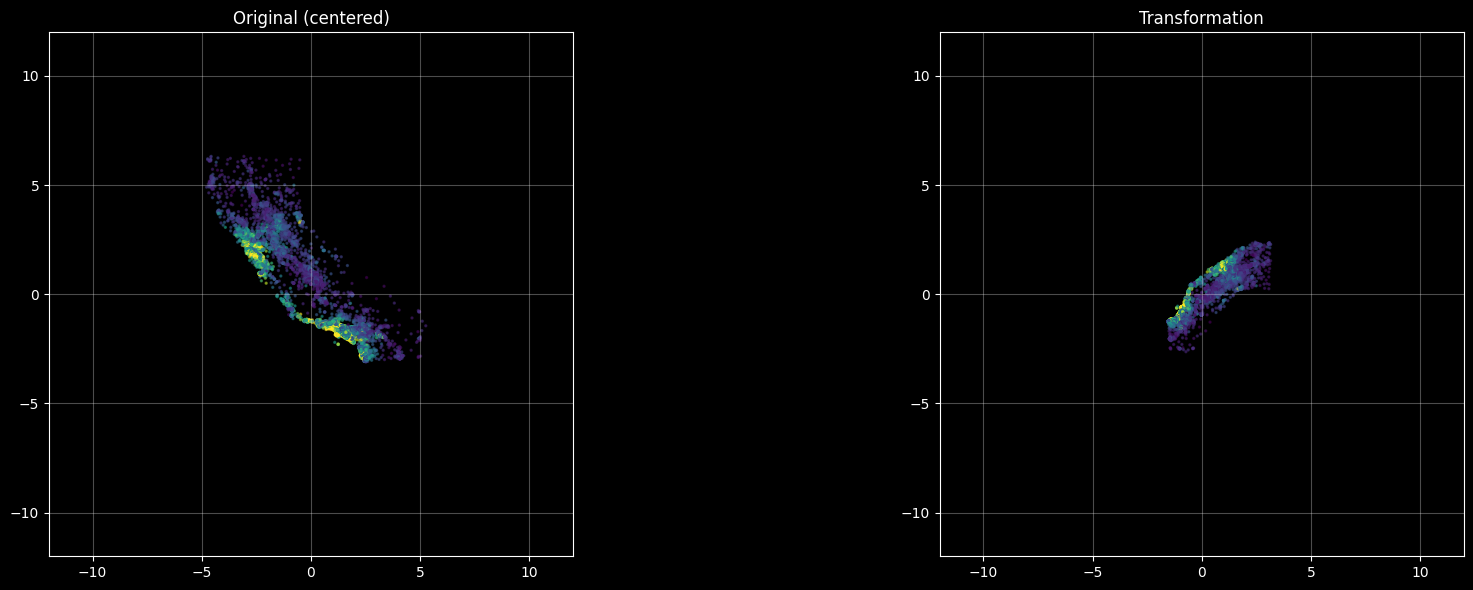

Distance between sample 0 and sample 10000:
  original: 1.6193
  transformation:  0.8096


In [ ]:
theta = np.deg2rad(90)
R = np.array([[np.cos(theta), -np.sin(theta)],
              [np.sin(theta),  np.cos(theta)]])
S = np.array([[0.5, 0.0],
              [0.0, 0.5]])
M = R @ S

P_transformation = P_centered @ M

fig, axes = plt.subplots(1, 2, figsize=(20, 6))
for ax, pts, title in zip(axes, [P_centered, P_transformation],
                          ['Original (centered)', 'Transformation']):
    ax.scatter(pts[:, 0], pts[:, 1], s=2, alpha=0.5, c=X[:, 8], cmap='viridis')
    ax.set_title(title)
    ax.set_xlim(-12, 12)
    ax.set_ylim(-12, 12)
    ax.set_aspect('equal')
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()


i, j = 0, 10000
print(f"Distance between sample {i} and sample {j}:")
print(f"  original: {np.linalg.norm(P_centered[i] - P_centered[j]):.4f}")
print(f"  transformation:  {np.linalg.norm(P_transformation[i] - P_transformation[j]):.4f}")

---

## Part 3: Descriptive Statistics

### Example 3a: Mean, trimmed mean and median under outliers

Fifteen heights in cm, then the same data with three entry errors.

In [ ]:
def trimmed_mean(x, p):
    """Mean after removing the p smallest and the p largest values."""
    x_sorted = np.sort(x)
    return np.mean(x_sorted[p:len(x) - p])

heights = np.array([165, 178, 182, 159, 174, 188, 171, 163, 179, 176, 184, 169, 167, 173, 181])

heights_bad = heights.copy()
heights_bad[[3, 10, 5]] = [26, 521, 680]

print(f"{'Estimate':<16} {'Clean':<12} {'With outliers':<14}")
print("=" * 42)
print(f"{'Mean':<16} {np.mean(heights):<12.2f} {np.mean(heights_bad):<14.2f}")
print(f"{'Trimmed (p=3)':<16} {trimmed_mean(heights, 3):<12.2f} {trimmed_mean(heights_bad, 3):<14.2f}")
print(f"{'Median':<16} {np.median(heights):<12.2f} {np.median(heights_bad):<14.2f}")

Real data already contains outliers. AveOccup is the average number of people per household.

In [ ]:
occup = X[:, 5]
p5 = int(0.05 * len(occup))          # 5% of the samples from each side

print(f"Mean:              {np.mean(occup):.3f}")
print(f"Trimmed mean (5%): {trimmed_mean(occup, p5):.3f}   (scipy: {stats.trim_mean(occup, 0.05):.3f})")
print(f"Median:            {np.median(occup):.3f}")
print(f"Five largest:      {np.round(np.sort(occup)[-5:], 1)}")

fig, axes = plt.subplots(1, 2, figsize=(18, 5))
axes[0].hist(occup, bins=100, color='cyan', alpha=0.7)
axes[0].set_yscale('log')
axes[0].set_title('AveOccup: all values (log count)')
axes[0].set_xlabel('AveOccup')
axes[0].grid(True, alpha=0.3)

axes[1].hist(occup[occup < 8], bins=100, color='cyan', alpha=0.7)
axes[1].axvline(np.mean(occup), color='red', linewidth=2, label=f'Mean = {np.mean(occup):.2f}')
axes[1].axvline(np.median(occup), color='lime', linewidth=2, label=f'Median = {np.median(occup):.2f}')
axes[1].set_title('AveOccup: values below 8')
axes[1].set_xlabel('AveOccup')
axes[1].legend()
axes[1].grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### Example 3b: Weighted mean

`Σ wᵢ xᵢ / Σ wᵢ`. Blocks have different populations, so the mean over blocks and the mean over people differ.

In [ ]:
house_age = X[:, 1]
population = X[:, 4]

weighted_age = (population @ house_age) / np.sum(population)

print(f"Mean HouseAge over blocks:            {np.mean(house_age):.3f}")
print(f"Mean HouseAge weighted by population: {weighted_age:.3f}   (np.average: {np.average(house_age, weights=population):.3f})")

### Example 3c: Variance, standard deviation and `n − 1`

The 20,640 blocks are treated as the population. Many small samples (n = 15) are drawn, and the variance of each is computed twice: dividing by `n` and by `n − 1`.

In [ ]:
income = X[:, 0]
sigma2 = np.sum((income - np.mean(income))**2) / len(income)      # population variance: divide by N

# one sample, step by step
sample = np.random.choice(income, 15, replace=False)
n = len(sample)
squared_deviations = (sample - np.mean(sample))**2
print(f"One sample:  divide by n = {np.sum(squared_deviations) / n:.4f}   divide by n - 1 = {np.sum(squared_deviations) / (n - 1):.4f}")
print(f"NumPy:       np.var(sample) = {np.var(sample):.4f}   np.var(sample, ddof=1) = {np.var(sample, ddof=1):.4f}\n")

# 10,000 samples, one per row
many_samples = np.random.choice(income, size=(10000, 15))
var_n = np.var(many_samples, axis=1, ddof=0)
var_n1 = np.var(many_samples, axis=1, ddof=1)

print(f"Population variance:          {sigma2:.4f}")
print(f"Average variance using n:     {np.mean(var_n):.4f}")
print(f"Average variance using n - 1: {np.mean(var_n1):.4f}")

plt.figure(figsize=(12, 5))
plt.hist(var_n, bins=80, alpha=0.5, color='red', label='divide by n')
plt.hist(var_n1, bins=80, alpha=0.5, color='cyan', label='divide by n - 1')
plt.axvline(np.mean(var_n), color='red', linewidth=2)
plt.axvline(np.mean(var_n1), color='cyan', linewidth=2)
plt.axvline(sigma2, color='white', linewidth=2, linestyle='--', label='population variance')
plt.xlim(0, 12)
plt.xlabel('Sample variance')
plt.title('10,000 samples of size 15')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

### Practice 3 (10 min)

Feature: AveRooms. `rooms_bad` is a copy in which 200 values were multiplied by 100.

1. On `rooms`, compute `rooms_mean`, `rooms_trimmed` (10% removed from each side) and `rooms_median`.
2. Compute the same three estimates on `rooms_bad`: `bad_mean`, `bad_trimmed`, `bad_median`.
3. `age_sample` holds 30 values of HouseAge. Compute its sample standard deviation `age_std` from scratch.